# Face Mask Detection

I wanted to put together a small face-mask classifier without downloading one of the gig-sized 'masked faces' datasets that float around. Idea: pull a small slice of Labeled Faces in the Wild via sklearn (cached, fairly small), draw a colored rectangle over the lower face of half the images to simulate a 'mask', and train a binary classifier on top.

Obviously a real model trained on actual masked faces would do something different — it would key on cloth texture and ear loops. Here the classifier basically learns 'is there a saturated colored patch around y=0.7?'. I want to be upfront about that. The pipeline is real; the supervision signal is a toy.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import fetch_lfw_people
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

np.random.seed(11); torch.manual_seed(11)

In [2]:
# LFW with min_faces_per_person=30 trims to a manageable ~2000 face crops
lfw = fetch_lfw_people(min_faces_per_person=30, resize=0.4, color=True)
X_faces = lfw.images  # (N, h, w, 3) in [0,1]
print('faces:', X_faces.shape)

# downsample further if it pulled too many
if len(X_faces) > 1200:
    idx = np.random.choice(len(X_faces), 1200, replace=False)
    X_faces = X_faces[idx]
    print('subsampled to', X_faces.shape)

faces: (2370, 50, 37, 3)
subsampled to (1200, 50, 37, 3)


In [3]:
def slap_mask(img, color=(0.1, 0.4, 0.95)):
    # img in [0,1], shape (h,w,3). Cover the lower ~40% with a flat color block.
    out = img.copy()
    h, w, _ = out.shape
    y0 = int(h * 0.55)
    out[y0:, :, :] = np.array(color)
    return out

# label half of them as masked, vary the colors a bit so the model can't memorize one RGB
n = len(X_faces)
labels = np.zeros(n, dtype=np.int64)
labels[: n // 2] = 1
perm = np.random.permutation(n)
X_faces = X_faces[perm]; labels = labels[perm]

mask_palette = np.array([(0.1, 0.4, 0.95), (0.9, 0.9, 0.9), (0.2, 0.2, 0.25), (0.05, 0.55, 0.4)])
X = np.zeros_like(X_faces)
for i, (f, y) in enumerate(zip(X_faces, labels)):
    if y == 1:
        c = mask_palette[i % len(mask_palette)]
        X[i] = slap_mask(f, color=tuple(c))
    else:
        X[i] = f

print('positives (masked):', int(labels.sum()), 'of', n)

positives (masked): 600 of 1200


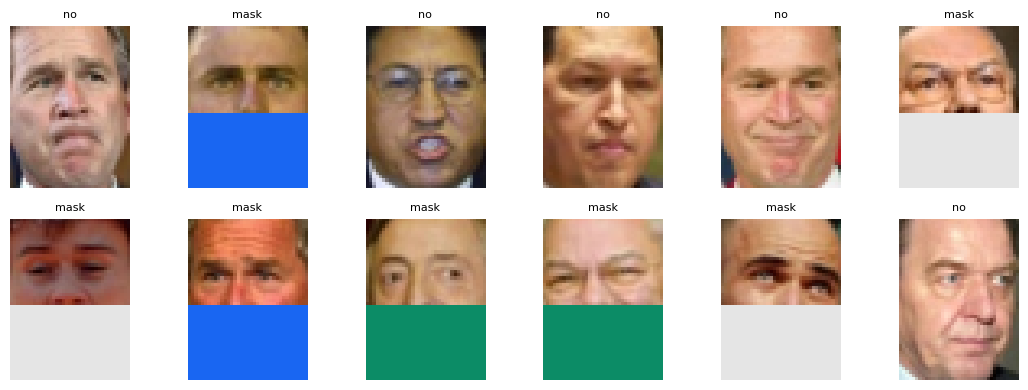

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, i in zip(axes.flat, np.random.choice(len(X), 12, replace=False)):
    ax.imshow(X[i]); ax.set_title('mask' if labels[i] == 1 else 'no', fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

In [5]:
# tensors: (N,3,H,W)
Xt = torch.tensor(X).permute(0, 3, 1, 2).float()
yt = torch.tensor(labels)

Xtr, Xte, ytr, yte = train_test_split(Xt.numpy(), yt.numpy(), test_size=0.2, stratify=yt.numpy(), random_state=11)
Xtr_t = torch.tensor(Xtr); Xte_t = torch.tensor(Xte)
ytr_t = torch.tensor(ytr); yte_t = torch.tensor(yte)
print('train', Xtr_t.shape, 'test', Xte_t.shape)

train torch.Size([960, 3, 50, 37]) test torch.Size([240, 3, 50, 37])


In [6]:
class MiniNet(nn.Module):
    def __init__(self, h, w):
        super().__init__()
        self.c1 = nn.Conv2d(3, 8, 5, padding=2)
        self.c2 = nn.Conv2d(8, 16, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        # compute fc size after two pools
        h2, w2 = h // 4, w // 4
        self.fc1 = nn.Linear(16 * h2 * w2, 32)
        self.fc2 = nn.Linear(32, 2)

    def forward(self, x):
        x = self.pool(F.relu(self.c1(x)))
        x = self.pool(F.relu(self.c2(x)))
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

_, _, H, W = Xtr_t.shape
net = MiniNet(H, W)
opt = torch.optim.Adam(net.parameters(), lr=1e-3)

batch = 32
for ep in range(3):
    perm = torch.randperm(len(Xtr_t))
    losses = []
    for i in range(0, len(perm), batch):
        idx = perm[i:i + batch]
        opt.zero_grad()
        out = net(Xtr_t[idx])
        loss = F.cross_entropy(out, ytr_t[idx])
        loss.backward(); opt.step()
        losses.append(loss.item())
    print(f'epoch {ep}  mean_loss={np.mean(losses):.4f}')

epoch 0  mean_loss=0.5851


epoch 1  mean_loss=0.1567


epoch 2  mean_loss=0.0240


In [7]:
net.eval()
with torch.no_grad():
    preds = net(Xte_t).argmax(1).numpy()

print(classification_report(yte, preds, target_names=['no_mask', 'mask']))
print('confusion:'); print(confusion_matrix(yte, preds))

              precision    recall  f1-score   support

     no_mask       1.00      0.99      1.00       120
        mask       0.99      1.00      1.00       120

    accuracy                           1.00       240
   macro avg       1.00      1.00      1.00       240
weighted avg       1.00      1.00      1.00       240

confusion:
[[119   1]
 [  0 120]]


## Takeaways

The accuracy here is going to look great because the task is too easy — a flat colored rectangle is a much stronger signal than a real mask. The right next step isn't tuning this model, it's swapping in actual masked-face data (the AIZOO or RMFD set) and seeing how much the same architecture loses. I'd also drop in MediaPipe face detection upstream so the input is always a tight face crop rather than the LFW thumbnails which already are.

Random thing I learned: the `min_faces_per_person` argument is the easiest knob for controlling dataset size from `fetch_lfw_people`, much cleaner than slicing afterwards.